# Task 4.0–4.5 — Khai phá luật kết hợp bằng Apriori

**Dữ liệu:** exploration 80%; test 20% được giữ nguyên, không dùng chọn ngưỡng hay xếp hạng luật. Một transaction là một observation, không phải khách hàng duy nhất. Seed chung: 42; Apriori là thuật toán tất định.

Notebook thực hiện mã hóa transaction, ba cấu hình, sinh/lọc luật, tối đa 10 luật cuối, chỉ số và số đếm, ô chèn ảnh giải tay riêng, đánh dấu luật ít quan sát. Chạy **Run All** từ kernel DBM301 (.venv).

**Quyết định đầu vào:** giữ các cột phân loại đã xử lý và `y`; bỏ `previous` khỏi thí nghiệm vì số đếm này chưa được rời rạc hóa (41 mức ở exploration), dùng `contacted_before` để thể hiện lịch sử liên hệ. Hai biến không tương đương hoàn toàn: quyết định này làm mất thông tin số lần liên hệ trước. Không sửa dữ liệu Task 2. Giới hạn itemset 3 item, nên LHS tối đa 2 điều kiện.

**Nguồn:** [TransactionEncoder](https://rasbt.github.io/mlxtend/user_guide/preprocessing/TransactionEncoder/), [Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/), [Association rules](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/).

In [13]:
from pathlib import Path
import json, hashlib, time, platform, inspect
import numpy as np
import pandas as pd
import mlxtend
from IPython.display import display, Markdown
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SOURCE = ROOT / 'data/processed/processed_exploration.csv'
OUT = ROOT / 'reports/apriori'
OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(SOURCE, sep=';')
assert len(df) > 0 and not df.isna().any().any()
assert set(df['y']) == {'yes', 'no'}
N = len(df)
print('Dữ liệu:', df.shape)
display(df.head(), df['y'].value_counts().rename('count').to_frame())
metadata = {'seed': SEED, 'python': platform.python_version(), 'pandas': pd.__version__,
            'mlxtend': mlxtend.__version__, 'source': str(SOURCE.relative_to(ROOT)),
            'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
            'n_observations': N, 'excluded_columns': ['previous'], 'max_itemset_length': 3}


Dữ liệu: (36168, 15)


,job,marital,education,default,housing,loan,contact,month,previous,poutcome,y,age_group,balance_group,campaign_group,contacted_before
0,technician,divorced,secondary,no,no,no,telephone,aug,0,unknown,no,middle_age,medium,2_3_calls,no
1,student,single,secondary,no,no,no,cellular,apr,7,failure,yes,young,high,4plus_calls,yes
2,technician,single,secondary,no,yes,no,cellular,aug,0,unknown,yes,middle_age,low,4plus_calls,no
3,unemployed,married,secondary,no,no,no,telephone,jul,0,unknown,no,middle_age,low,4plus_calls,no
4,technician,married,secondary,no,no,no,cellular,aug,0,unknown,no,middle_age,low,4plus_calls,no


,count
y,
no,31937
yes,4231


## 4.0 — Transaction và one-hot encoding
Mỗi item có dạng `attribute=value`. Giữ nhãn `y` để khai phá luật hướng đến phản hồi. Không gộp các item `no` của nhiều thuộc tính. `obs_id` là vị trí dòng exploration (bắt đầu từ 1), không đưa vào itemset, không phải mã khách hàng.

In [ ]:
mining_df = df.drop(columns=['previous']).astype(str)
transactions = [[f'{c}={v}' for c, v in zip(mining_df.columns, row)]
                for row in mining_df.itertuples(index=False, name=None)]
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
assert onehot.to_numpy().dtype == bool
assert (onehot.sum(axis=1) == mining_df.shape[1]).all()
assert (onehot[['y=yes', 'y=no']].sum(axis=1) == 1).all()
pd.DataFrame({'obs_id': range(1, N+1), 'items_json': [json.dumps(t) for t in transactions]}).to_csv(OUT/'transactions.csv', index=False)
onehot.to_csv(OUT/'onehot_exploration.csv', index=False)
pd.DataFrame({'item': onehot.columns, 'count': onehot.sum().values,
              'support': onehot.mean().values}).to_csv(OUT/'item_dictionary.csv', index=False)
print('One-hot:', onehot.shape)
print('Transaction 1:', transactions[0])
display(onehot.head())

One-hot: (36168, 58)
Transaction 1: ['job=technician', 'marital=divorced', 'education=secondary', 'default=no', 'housing=no', 'loan=no', 'contact=telephone', 'month=aug', 'poutcome=unknown', 'y=no', 'age_group=middle_age', 'balance_group=medium', 'campaign_group=2_3_calls', 'contacted_before=no']


,age_group=middle_age,age_group=senior,age_group=young,balance_group=high,balance_group=low,balance_group=medium,balance_group=negative,campaign_group=1_call,campaign_group=2_3_calls,campaign_group=4plus_calls,...,month=may,month=nov,month=oct,month=sep,poutcome=failure,poutcome=other,poutcome=success,poutcome=unknown,y=no,y=yes
0,True,False,False,False,False,True,False,False,True,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,True,True,False,False,False,False,False,True,...,False,False,False,False,True,False,False,False,False,True
2,True,False,False,False,True,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,True
3,True,False,False,False,True,False,False,False,False,True,...,False,False,False,False,False,False,False,True,True,False
4,True,False,False,False,True,False,False,False,False,True,...,False,False,False,False,False,False,False,True,True,False


## 4.1 — Ba cấu hình ngưỡng
Chỉ thay minimum support 1%, 2%, 3%; confidence cố định 60%, max_len=3, dữ liệu và bộ lọc giống nhau. Ngưỡng là lựa chọn thí nghiệm của nhóm. Dùng `low_memory=True` để hạn chế bộ nhớ; thời gian phụ thuộc máy. Ghi số itemset theo độ dài và số luật qua các bước. Apriori cắt tỉa dựa trên tính chất: tập chứa một tập con không phổ biến cũng không phổ biến.

In [15]:
CONFIGS = [{'config': name, 'min_support': support, 'min_confidence': 0.60, 'max_len': 3}
           for name, support in [('A', .01), ('B', .02), ('C', .03)]]
MIN_COUNT = 100
pd.DataFrame(CONFIGS).to_csv(OUT/'configs.csv', index=False)

def itemtext(items):
    return ' & '.join(sorted(items))

def mask(items):
    return onehot[list(items)].all(axis=1)

def metrics_table(rules):
    rows = []
    for _, r in rules.iterrows():
        A, B = r['antecedents'], r['consequents']
        ma, mb = mask(A), mask(B)
        na, nb, nab = int(ma.sum()), int(mb.sum()), int((ma & mb).sum())
        support, confidence = nab/N, nab/na
        lift = confidence/(nb/N)
        leverage = support-(na/N)*(nb/N)
        for key, val in [('support', support), ('confidence', confidence), ('lift', lift), ('leverage', leverage)]:
            assert np.isclose(float(r[key]), val), (key, r[key], val)
        rows.append({'lhs': itemtext(A), 'rhs': itemtext(B), 'lhs_length': len(A),
                     'n_total': N, 'antecedent_count': na, 'consequent_count': nb,
                     'supporting_observations': nab, 'support': support, 'confidence': confidence,
                     'lift': lift, 'leverage': leverage, 'low_count': nab < MIN_COUNT})
    return pd.DataFrame(rows, columns=['lhs','rhs','lhs_length','n_total','antecedent_count',
        'consequent_count','supporting_observations','support','confidence','lift','leverage','low_count'])

logs, all_tables = [], []
for cfg in CONFIGS:
    start = time.perf_counter()
    fi = apriori(onehot, min_support=cfg['min_support'], use_colnames=True,
                 max_len=cfg['max_len'], low_memory=True)
    mining_seconds = time.perf_counter()-start
    fi_export = fi.copy()
    fi_export['length'] = fi_export['itemsets'].map(len)
    fi_export['itemsets'] = fi_export['itemsets'].map(itemtext)
    fi_export.to_csv(OUT/f"frequent_itemsets_{cfg['config']}.csv", index=False)
    kwargs = {'metric':'confidence', 'min_threshold':cfg['min_confidence']}
    if 'num_itemsets' in inspect.signature(association_rules).parameters:
        kwargs['num_itemsets'] = N
    raw = association_rules(fi, **kwargs)
    target = raw[raw['consequents'].map(lambda x: x in [frozenset({'y=yes'}), frozenset({'y=no'})])
                 & raw['antecedents'].map(lambda x: len(x)>0 and not any(i.startswith('y=') for i in x))].copy()
    table = metrics_table(target)
    table.insert(0, 'config', cfg['config'])
    table.to_csv(OUT/f"rule_metrics_{cfg['config']}.csv", index=False)
    all_tables.append(table)
    log = {**cfg, 'minimum_joint_count': int(np.ceil(cfg['min_support']*N)),
           'frequent_itemsets':len(fi), 'rules_confidence_pass':len(raw), 'target_rules':len(table),
           'target_yes':int((table['rhs']=='y=yes').sum()), 'target_no':int((table['rhs']=='y=no').sum()),
           'low_count_rules':int(table['low_count'].sum()),
           'eligible_rules':int(((table['lift']>1)&(~table['low_count'])).sum()),
           'mining_seconds':mining_seconds, 'total_seconds':time.perf_counter()-start}
    log.update({f'itemsets_length_{k}':int((fi['itemsets'].map(len)==k).sum()) for k in [1,2,3]})
    logs.append(log)
    print(cfg['config'], 'hoàn thành:', log['target_rules'], 'luật hướng đến y')
logs = pd.DataFrame(logs)
logs.to_csv(OUT/'experiment_logs.csv', index=False)
all_rules = pd.concat(all_tables, ignore_index=True)
all_rules.to_csv(OUT/'rule_metrics_all_configs.csv', index=False)
display(logs)

A hoàn thành: 796 luật hướng đến y
B hoàn thành: 619 luật hướng đến y
C hoàn thành: 505 luật hướng đến y


,config,min_support,min_confidence,max_len,minimum_joint_count,frequent_itemsets,rules_confidence_pass,target_rules,target_yes,target_no,low_count_rules,eligible_rules,mining_seconds,total_seconds,itemsets_length_1,itemsets_length_2,itemsets_length_3
0,A,0.01,0.6,3,362,6696,7264,796,9,787,0,469,0.485744,1.605594,56,885,5755
1,B,0.02,0.6,3,724,4483,5684,619,4,615,0,377,0.453330,1.458469,52,680,3751
2,C,0.03,0.6,3,1086,3418,4663,505,0,505,0,316,0.333594,1.098187,49,563,2806


## 4.2 — Sinh, lọc và chọn tối đa 10 luật
RHS phải đúng một item `y=yes` hoặc `y=no`; LHS không có y. Chọn luật lift>1, ít nhất 100 dòng thỏa đồng thời LHS và RHS. Loại trùng giữa cấu hình; xếp lift, confidence, số quan sát giảm dần, sau đó tên luật để xử lý hòa. Lấy 10 luật chung, không ép số lượng theo nhãn. Đây là lựa chọn ưu tiên mức liên hệ tương đối, không đảm bảo đa dạng hay không trùng lặp nội dung.

`supporting_observations` là **số dòng thỏa A và B**, khác số dòng chỉ thỏa A. Xuất cả danh sách obs_id để truy vết. Confidence cao của y=no phải so với tỷ lệ no nền.

In [16]:
unique_rules = all_rules.drop_duplicates(['lhs','rhs']).drop(columns='config').copy()
config_membership = all_rules.groupby(['lhs','rhs'])['config'].agg(lambda x: ','.join(sorted(set(x))))
unique_rules['configs'] = [config_membership.loc[(r.lhs,r.rhs)] for r in unique_rules.itertuples()]
eligible = unique_rules[(unique_rules['lift']>1)&(~unique_rules['low_count'])].copy()
top = eligible.sort_values(['lift','confidence','supporting_observations','lhs','rhs'],
    ascending=[False,False,False,True,True]).head(10).reset_index(drop=True)
top.insert(0, 'rule_id', [f'R{i:02}' for i in range(1,len(top)+1)])
assert len(top)<=10 and len(top)>0
assert top['rhs'].isin(['y=yes','y=no']).all()
assert top['lhs'].map(lambda s: not any(i.startswith('y=') for i in s.split(' & '))).all()
top.to_csv(OUT/'top_10_rules.csv', index=False)
unique_rules.to_csv(OUT/'unique_target_rules.csv', index=False)
support_rows = []
for r in top.itertuples():
    matched = mask(r.lhs.split(' & ')) & mask([r.rhs])
    ids = np.flatnonzero(matched.to_numpy())+1
    assert len(ids)==r.supporting_observations
    support_rows.extend({'rule_id':r.rule_id, 'obs_id':int(i)} for i in ids)
pd.DataFrame(support_rows).to_csv(OUT/'supporting_observation_ids.csv', index=False)
display(top)
print('Tỷ lệ nền yes:', (df.y=='yes').mean(), '| no:', (df.y=='no').mean())

,rule_id,lhs,rhs,lhs_length,n_total,antecedent_count,consequent_count,supporting_observations,support,confidence,lift,leverage,low_count,configs
0,R01,housing=no & poutcome=success,y=yes,2,36168,832,4231,582,0.016092,0.699519,5.979724,0.013401,False,A
1,R02,campaign_group=1_call & poutcome=success,y=yes,2,36168,678,4231,458,0.012663,0.675516,5.774538,0.010470,False,A
2,R03,marital=married & poutcome=success,y=yes,2,36168,659,4231,430,0.011889,0.652504,5.577820,0.009757,False,A
3,R04,loan=no & poutcome=success,y=yes,2,36168,1141,4231,743,0.020543,0.651183,5.566531,0.016853,False,"A,B"
4,R05,contact=cellular & poutcome=success,y=yes,2,36168,1104,4231,715,0.019769,0.647645,5.536285,0.016198,False,A
5,R06,default=no & poutcome=success,y=yes,2,36168,1204,4231,779,0.021538,0.647010,5.530857,0.017644,False,"A,B"
6,R07,contacted_before=yes & poutcome=success,y=yes,2,36168,1205,4231,779,0.021538,0.646473,5.526267,0.017641,False,"A,B"
7,R08,poutcome=success,y=yes,1,36168,1205,4231,779,0.021538,0.646473,5.526267,0.017641,False,"A,B"
8,R09,age_group=middle_age & poutcome=success,y=yes,2,36168,819,4231,514,0.014211,0.627595,5.364888,0.011562,False,A
9,R10,contact=unknown & marital=married,y=no,2,36168,6402,31937,6200,0.171422,0.968447,1.096747,0.015122,False,"A,B,C"


Tỷ lệ nền yes: 0.11698186241981863 | no: 0.8830181375801813


## 4.3 — Báo support, confidence, lift, leverage và supporting observations
Các chỉ số đã được tính từ số đếm trong `metrics_table`, đối chiếu với mlxtend bằng assert và xuất CSV. Cell dưới hiển thị riêng bảng đúng yêu cầu 4.3. Supporting observations = số dòng thỏa đồng thời LHS và RHS, không phải antecedent_count.


In [17]:
display(top[['rule_id','lhs','rhs','support','confidence','lift','leverage','supporting_observations']])


,rule_id,lhs,rhs,support,confidence,lift,leverage,supporting_observations
0,R01,housing=no & poutcome=success,y=yes,0.016092,0.699519,5.979724,0.013401,582
1,R02,campaign_group=1_call & poutcome=success,y=yes,0.012663,0.675516,5.774538,0.010470,458
2,R03,marital=married & poutcome=success,y=yes,0.011889,0.652504,5.577820,0.009757,430
3,R04,loan=no & poutcome=success,y=yes,0.020543,0.651183,5.566531,0.016853,743
4,R05,contact=cellular & poutcome=success,y=yes,0.019769,0.647645,5.536285,0.016198,715
5,R06,default=no & poutcome=success,y=yes,0.021538,0.647010,5.530857,0.017644,779
6,R07,contacted_before=yes & poutcome=success,y=yes,0.021538,0.646473,5.526267,0.017641,779
7,R08,poutcome=success,y=yes,0.021538,0.646473,5.526267,0.017641,779
8,R09,age_group=middle_age & poutcome=success,y=yes,0.014211,0.627595,5.364888,0.011562,514
9,R10,contact=unknown & marital=married,y=no,0.171422,0.968447,1.096747,0.015122,6200


## 4.4 — Minh họa một phép tính tay từ số đếm thực tế
**Chèn ảnh lời giải tay riêng tại đây.** Ví dụ: `poutcome=success → y=yes` (R08). Lời giải được trình bày ngoài notebook để chụp màn hình; notebook không chứa lời giải hay code tạo lời giải.

<!-- Dán ảnh vào Markdown cell này bằng Edit > Insert Image hoặc kéo thả ảnh, tùy phiên bản Jupyter. -->
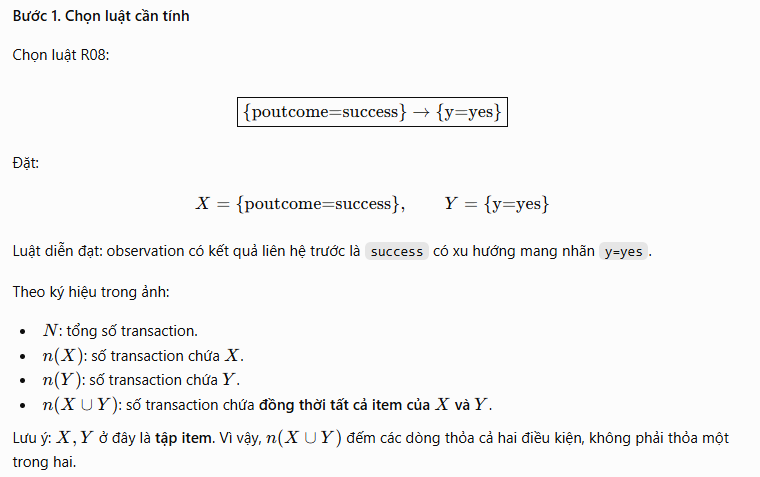
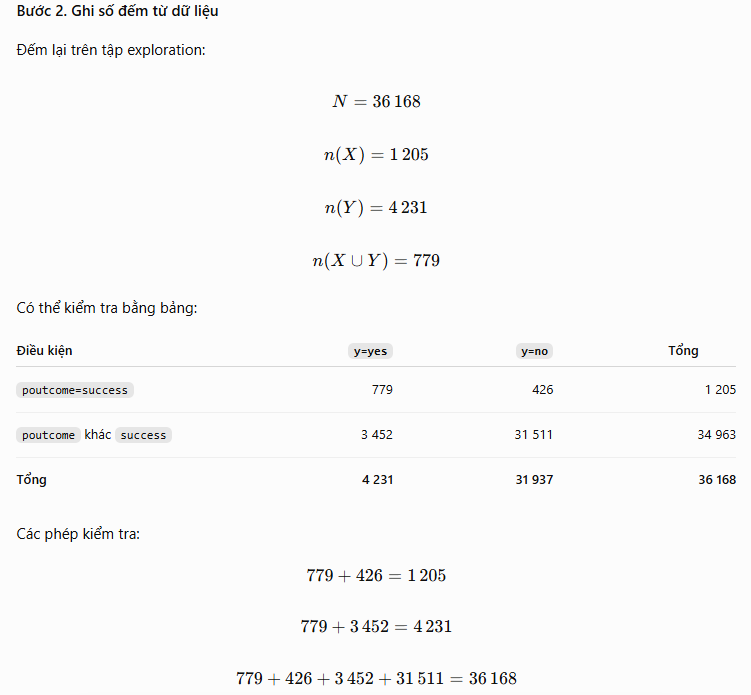
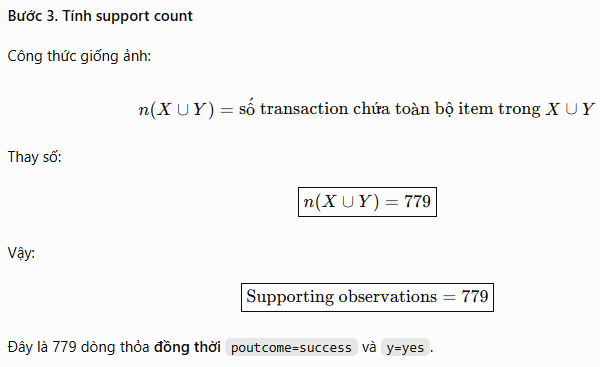
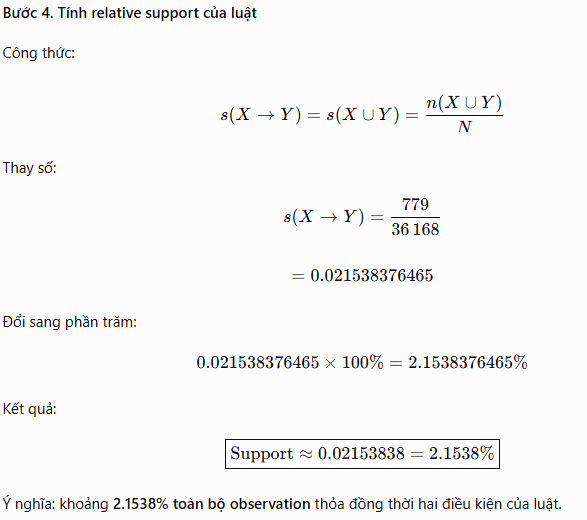
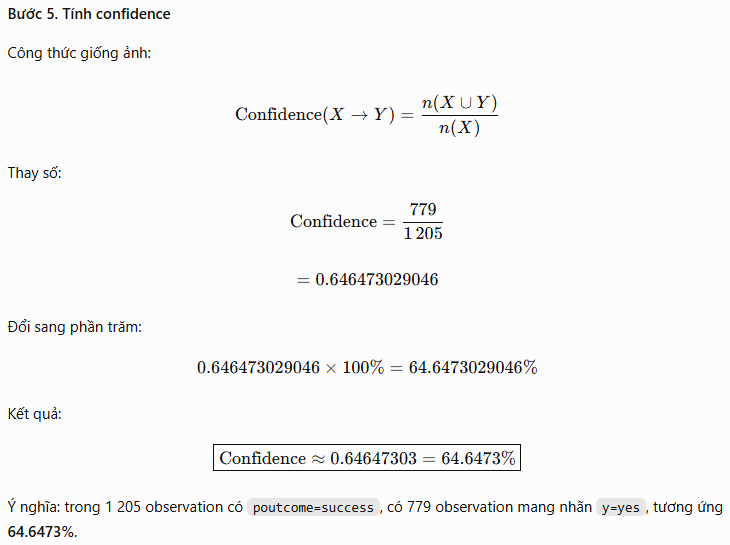
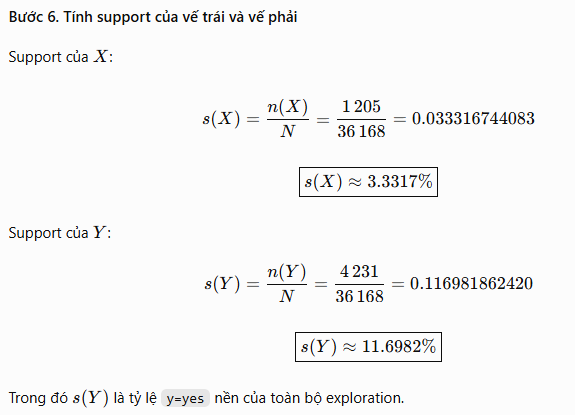
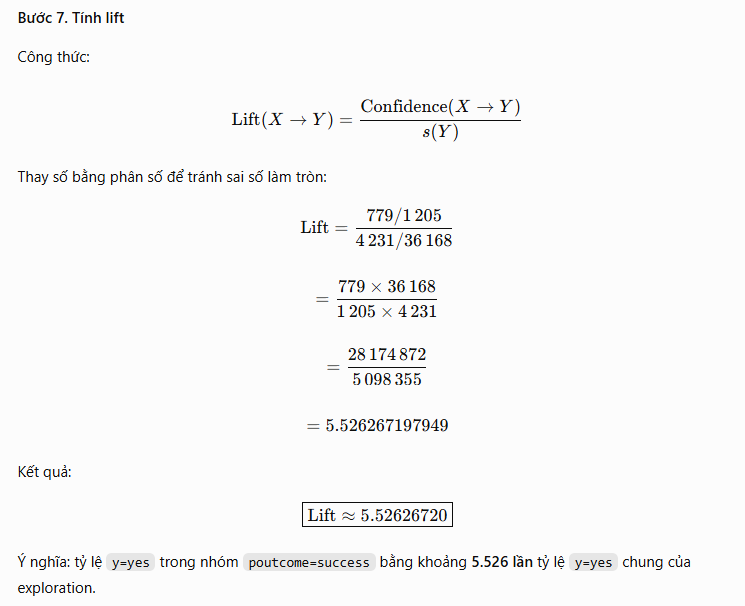
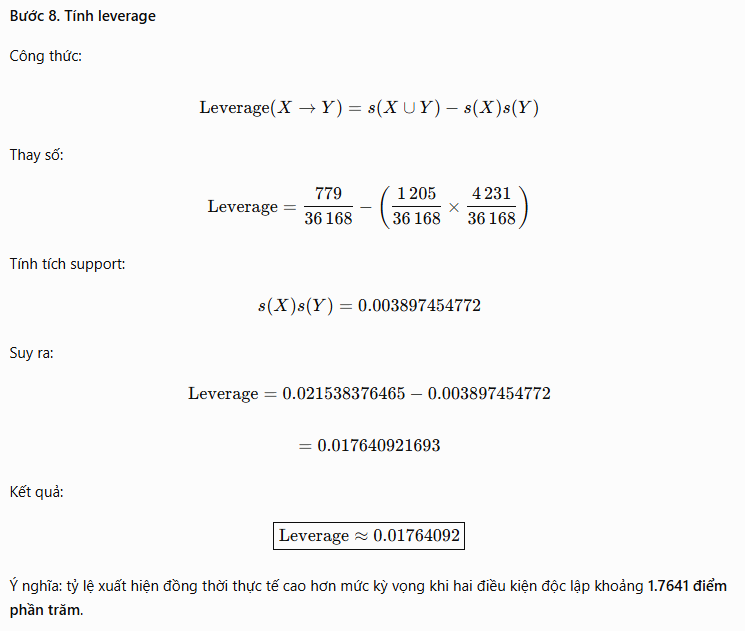
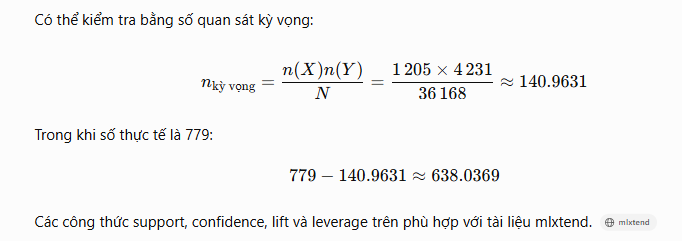
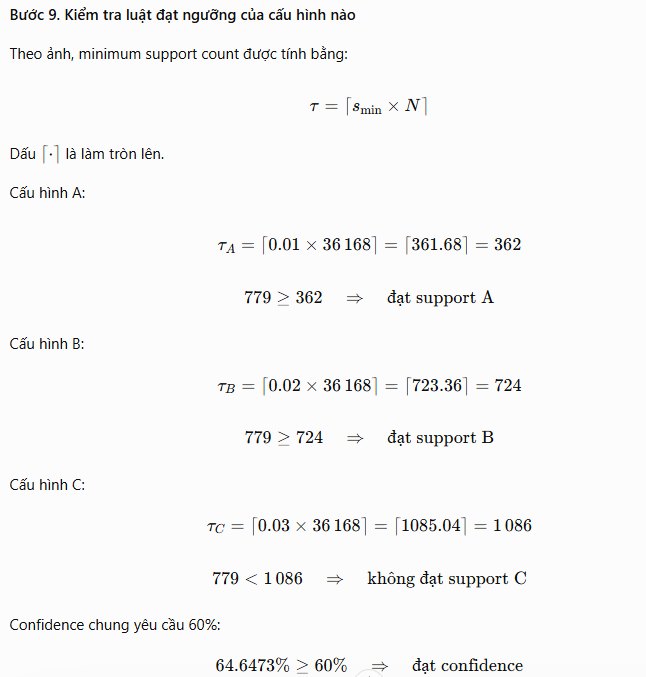
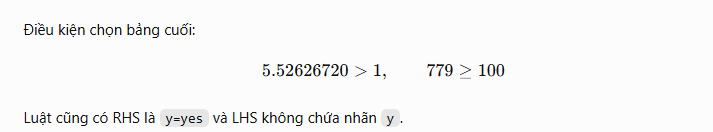
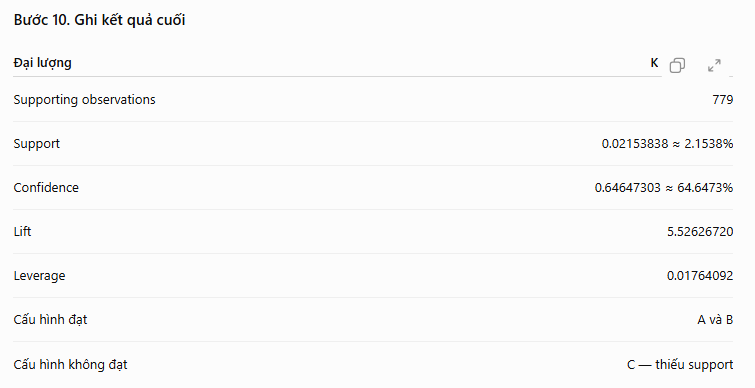

## 4.5 — Loại/đánh dấu luật có supporting observations quá thấp
**Tiêu chí của nhóm:** đánh dấu `low_count=True` khi số dòng thỏa đồng thời LHS và RHS nhỏ hơn 100; loại những luật đó khỏi danh sách đủ điều kiện. Mốc 100 là lựa chọn vận hành của nhóm, không phải mốc chuẩn do mlxtend quy định, không bảo đảm ý nghĩa thống kê.

**Kết quả đếm lại dữ liệu exploration:** 796 luật hướng đến y duy nhất; 0 luật dưới 100. Do minimum support thấp nhất = 1%, tất cả luật được sinh đã có ít nhất ceil(0.01 × 36168) = 362 supporting observations. Tiêu chí 100 không loại thêm luật nào trong thí nghiệm này. Không được ghi rằng đã loại R01–R10 vì low_count.

**Căn cứ tài liệu:** [mlxtend Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/) định nghĩa support là tỷ lệ transaction chứa itemset và dùng min_support để tìm frequent itemsets. [mlxtend Association rules, Metrics](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/#metrics) định nghĩa rule support là support của itemset hợp LHS và RHS. Vì vậy điều kiện support ≥ s_min tương đương count ≥ ceil(s_min × N). Hai tài liệu này hỗ trợ cách tính/lọc tần suất; không quy định phải dùng count=100 hay khẳng định mọi luật hiếm đều vô ích.

**Phân biệt hai cách loại:**
- Loại vì low_count < 100: không có luật nào.
- Không đạt minimum support của cấu hình: A cần 362, B cần 724, C cần 1086. R01, R02, R03, R05, R09 không đạt B và C; R04, R06, R07, R08 đạt B nhưng không đạt C; R10 đạt cả ba. Đây là loại theo ngưỡng thí nghiệm, không phải chứng minh các luật đó sai.

R07 có số đếm và chỉ số bằng R08: nên ghi chú trùng thông tin trên exploration, không đánh dấu low_count. Confidence cao/lift cao không tự chứng minh quan hệ nhân quả hoặc khả năng tổng quát hóa.


In [18]:
flagged = unique_rules[unique_rules.low_count].copy()
flagged.to_csv(OUT/'low_count_rules.csv', index=False)
# Báo rõ từng luật bị đánh dấu; nếu rỗng, ghi đúng là không có.
if flagged.empty:
    print(f'Không có luật có supporting observations < {MIN_COUNT}.')
else:
    display(flagged[['lhs','rhs','supporting_observations','support','confidence','lift']])
audit = top[['rule_id','lhs','rhs','supporting_observations']].copy()
audit['low_count_lt_100'] = audit['supporting_observations'] < MIN_COUNT
for cfg in CONFIGS:
    threshold = int(np.ceil(cfg['min_support'] * N))
    audit[f"minimum_count_{cfg['config']}"] = threshold
    audit[f"pass_support_{cfg['config']}"] = audit['supporting_observations'] >= threshold
# Đây là kiểm tra support; pass_support không thay thế toàn bộ bộ lọc sinh luật.
audit.to_csv(OUT/'rule_selection_audit.csv', index=False)
display(audit)
metadata.update({'configs':CONFIGS, 'minimum_supporting_observations':MIN_COUNT,
                 'unique_target_rules':len(unique_rules), 'final_rules':len(top),
                 'low_count_rules':len(flagged)})
(OUT/'run_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
assert not top['low_count'].any()
print(f'{len(unique_rules)} luật duy nhất; {len(eligible)} luật đủ điều kiện; {len(top)} luật cuối; {len(flagged)} luật low_count.')


Không có luật có supporting observations < 100.


,rule_id,lhs,rhs,supporting_observations,low_count_lt_100,minimum_count_A,pass_support_A,minimum_count_B,pass_support_B,minimum_count_C,pass_support_C
0,R01,housing=no & poutcome=success,y=yes,582,False,362,True,724,False,1086,False
1,R02,campaign_group=1_call & poutcome=success,y=yes,458,False,362,True,724,False,1086,False
2,R03,marital=married & poutcome=success,y=yes,430,False,362,True,724,False,1086,False
3,R04,loan=no & poutcome=success,y=yes,743,False,362,True,724,True,1086,False
4,R05,contact=cellular & poutcome=success,y=yes,715,False,362,True,724,False,1086,False
5,R06,default=no & poutcome=success,y=yes,779,False,362,True,724,True,1086,False
6,R07,contacted_before=yes & poutcome=success,y=yes,779,False,362,True,724,True,1086,False
7,R08,poutcome=success,y=yes,779,False,362,True,724,True,1086,False
8,R09,age_group=middle_age & poutcome=success,y=yes,514,False,362,True,724,False,1086,False
9,R10,contact=unknown & marital=married,y=no,6200,False,362,True,724,True,1086,True


796 luật duy nhất; 469 luật đủ điều kiện; 10 luật cuối; 0 luật low_count.


## Nhận xét kết quả đã chạy
- A: 6.696 itemset, 796 luật hướng đến y (9 yes, 787 no).
- B: 4.483 itemset, 619 luật hướng đến y (4 yes, 615 no).
- C: 3.418 itemset, 505 luật hướng đến y (0 yes, 505 no).
- Khi tăng support, số itemset và luật giảm. Ở C không có luật yes đạt đồng thời support 3% và confidence 60%; điều này không có nghĩa không tồn tại mối liên hệ với yes.
- Bảng cuối có 9 luật yes và 1 luật no. Luật đứng đầu: housing=no & poutcome=success → y=yes; 582 quan sát hỗ trợ, confidence 69,95%, lift 5,98.
- Các luật yes đều chứa poutcome=success: bảng xếp hạng tập trung vào một tín hiệu, không đại diện 9 insight độc lập. Luật contacted_before=yes & poutcome=success có cùng số đếm và chỉ số với luật poutcome=success; điều kiện thêm không cải thiện kết quả ở tập này.
- 0 luật low_count: support 1% đã yêu cầu ít nhất 362 quan sát, lớn hơn mốc 100.
- Đây là kết quả mô tả exploration; chưa đánh giá trên test. Thời gian log là thời gian của máy thực thi, có thể khác trên máy Windows của bạn.
